# Auto Insurance Fraud Detection

This notebook contains the analysis for the dissertation. It loads the carclaims
auto insurance dataset, cleans it, and compares several ways of dealing with the
class imbalance problem using a fixed gradient boosting classifier. It also runs
an unsupervised Isolation Forest for comparison.

**How to run:** run the cells from top to bottom. The dataset file
`fraud_oracle.csv` should be in the data/ folder.

**Libraries needed:**
```
pip install pandas numpy scikit-learn matplotlib lightgbm imbalanced-learn
```


## 1. Imports and settings

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve)

# LightGBM is the supervised model used in this study
from lightgbm import LGBMClassifier

# imbalanced-learn provides the resampling methods
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.float_format', lambda v: f'{v:.3f}')

## 2. Load the data

The dataset has 15,420 claims and 33 columns. The target column is
`FraudFound_P` (1 = fraud, 0 = genuine).

In [3]:
df = pd.read_csv('data/fraud_oracle.csv')
print('Shape:', df.shape)
print('Fraud rate: {:.2f}%'.format(df['FraudFound_P'].mean() * 100))
df.head()

Shape: (15420, 33)
Fraud rate: 5.99%


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


## 3. Clean the data

Three cleaning steps are applied, based on issues found during exploration:

1. `PolicyNumber` is just an ID, so it is dropped.
2. Some rows have `Age` = 0, which is not possible, so these are replaced with the
   median age of the valid rows.
3. One row has an invalid `MonthClaimed` value of '0', so that single row is removed.

In [4]:
# 1. drop the identifier column
df = df.drop(columns=['PolicyNumber'])

# 2. fix impossible ages (Age == 0)
n_bad_age = (df['Age'] == 0).sum()
median_age = int(df.loc[df['Age'] > 0, 'Age'].median())
df.loc[df['Age'] == 0, 'Age'] = median_age
print(f'Replaced {n_bad_age} rows where Age was 0 with median age {median_age}')

# 3. drop the single invalid row
before = len(df)
df = df[df['MonthClaimed'] != '0'].reset_index(drop=True)
print(f'Dropped {before - len(df)} invalid row(s)')
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())


Replaced 320 rows where Age was 0 with median age 39
Dropped 1 invalid row(s)
Missing values: 0
Duplicate rows: 0


## 4. Quick look at the data (EDA)

Two simple checks. First the class balance, then the fraud rate for a few
categorical features, to confirm the features carry some signal.

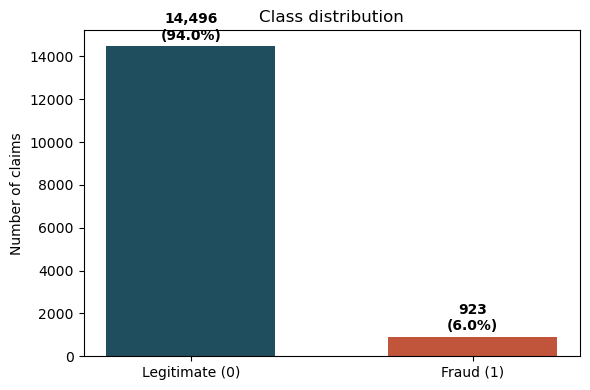

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df['FraudFound_P'].value_counts().sort_index()
bars = ax.bar(['Legitimate (0)', 'Fraud (1)'], counts.values,
              color=['#1F4E5F', '#C1553B'], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 150,
            f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('Number of claims')
ax.set_title('Class distribution')
plt.tight_layout(); plt.show()


Fraud rate by Fault (%):
Fault
Policy Holder   7.890
Third Party     0.880
Name: FraudFound_P, dtype: float64

Fraud rate by BasePolicy (%):
BasePolicy
All Perils   10.160
Collision     7.300
Liability     0.720
Name: FraudFound_P, dtype: float64

Fraud rate by VehicleCategory (%):
VehicleCategory
Sedan      8.220
Sport      1.570
Utility   11.250
Name: FraudFound_P, dtype: float64


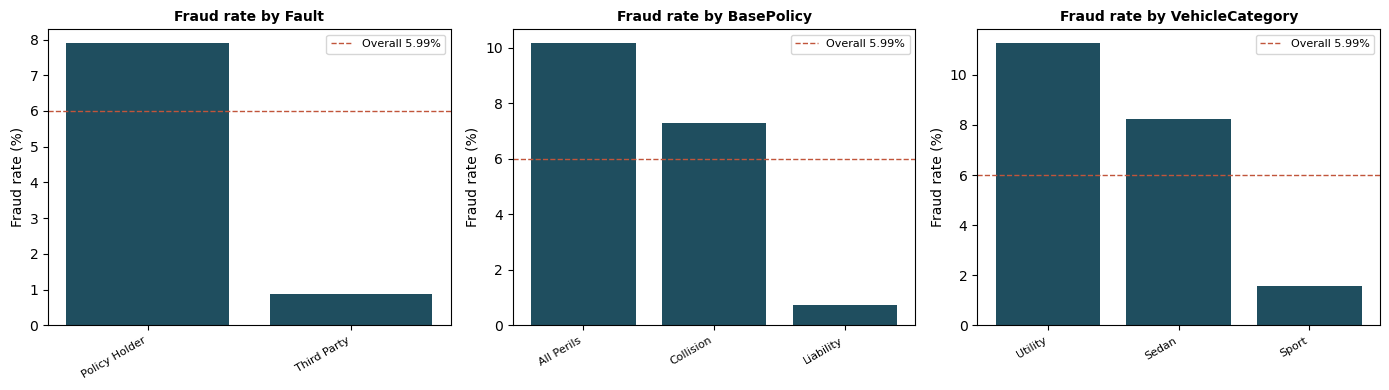

In [6]:
for col in ['Fault', 'BasePolicy', 'VehicleCategory']:
    print(f'\nFraud rate by {col} (%):')
    print((df.groupby(col)['FraudFound_P'].mean() * 100).round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, ['Fault', 'BasePolicy', 'VehicleCategory']):
    rate = df.groupby(col)['FraudFound_P'].mean().sort_values(ascending=False) * 100
    ax.bar(range(len(rate)), rate.values, color='#1F4E5F')
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels(rate.index, rotation=30, ha='right', fontsize=8)
    ax.set_title(f'Fraud rate by {col}', fontweight='bold', fontsize=10)
    ax.set_ylabel('Fraud rate (%)')
    ax.axhline(5.99, color='#C1553B', ls='--', lw=1, label='Overall 5.99%')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('image2.png', dpi=300, bbox_inches='tight')

plt.show()

## 5. Encode the features

The dataset is mostly categorical. Because the models used here are tree based,
the categorical columns are turned into integer codes with ordinal encoding.
Tree models can use these integer codes directly, so one hot encoding is not needed.

In [7]:
y = df['FraudFound_P'].values
X = df.drop(columns=['FraudFound_P'])

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f'Categorical columns: {len(cat_cols)}, Numerical columns: {len(num_cols)}')

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_enc = X.copy()
X_enc[cat_cols] = encoder.fit_transform(X[cat_cols])
X_enc = X_enc.astype(float).values

Categorical columns: 24, Numerical columns: 7


## 6. Train / test split (done BEFORE resampling)

This is the most important step for a fair result. The data is split into a
training set and a test set **before** any resampling. A stratified split keeps
the same 6% fraud rate in both parts. Resampling is only applied to the training
set later on. The test set is never resampled, so it always reflects the real,
natural balance of the data. This avoids data leakage.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f'Train: {X_train.shape[0]} rows, fraud rate {y_train.mean()*100:.2f}%')
print(f'Test:  {X_test.shape[0]} rows, fraud rate {y_test.mean()*100:.2f}%  (kept untouched)')

Train: 11564 rows, fraud rate 5.98%
Test:  3855 rows, fraud rate 5.99%  (kept untouched)


Effect of Resampling on the Training Data

In [9]:
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek

balance_rows = []
balance_rows.append(['Before (original)', (y_train==0).sum(), (y_train==1).sum()])

for name, sampler in [('SMOTE', SMOTE(random_state=RANDOM_STATE)),
                      ('ADASYN', ADASYN(random_state=RANDOM_STATE)),
                      ('SMOTE-Tomek', SMOTETomek(random_state=RANDOM_STATE))]:
    Xr, yr = sampler.fit_resample(X_train, y_train)
    balance_rows.append([name, (yr==0).sum(), (yr==1).sum()])

balance_df = pd.DataFrame(balance_rows, columns=['Condition', 'Genuine (0)', 'Fraud (1)'])
balance_df['Total'] = balance_df['Genuine (0)'] + balance_df['Fraud (1)']
balance_df['Balance'] = '1 : ' + (balance_df['Genuine (0)'] / balance_df['Fraud (1)']).round(2).astype(str)
balance_df

,Condition,Genuine (0),Fraud (1),Total,Balance
0,Before (original),10872,692,11564,1 : 15.71
1,SMOTE,10872,10872,21744,1 : 1.0
2,ADASYN,10872,10960,21832,1 : 0.99
3,SMOTE-Tomek,10870,10870,21740,1 : 1.0


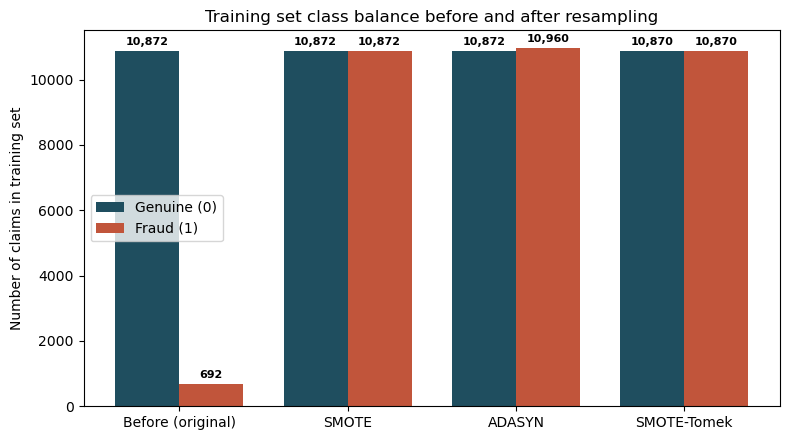

In [10]:
methods = balance_df['Condition'].tolist()
genuine = balance_df['Genuine (0)'].tolist()
fraud   = balance_df['Fraud (1)'].tolist()

x = np.arange(len(methods))
w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
bars1 = ax.bar(x - w/2, genuine, w, label='Genuine (0)', color='#1F4E5F')
bars2 = ax.bar(x + w/2, fraud, w, label='Fraud (1)', color='#C1553B')

# put the number on top of each bar
for b in list(bars1) + list(bars2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 120,
            f'{int(b.get_height()):,}', ha='center', va='bottom',
            fontsize=8, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel('Number of claims in training set')
ax.set_title('Training set class balance before and after resampling')
ax.legend()
plt.tight_layout()
plt.savefig('image3.png', dpi=300, bbox_inches='tight')

plt.show()

## 7. Model and evaluation settings

The same LightGBM model is used in every supervised experiment, so that only the
training data changes between them. Keeping the model fixed is what makes the
comparison of resampling methods fair.

For the threshold based metrics (precision, recall, F1) the decision threshold is
chosen to give the best F1 on the precision recall curve, so each model is judged
at its own best balance point. PR-AUC and ROC-AUC do not need a threshold.

In [11]:
def make_model():
    return LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        verbose=-1
    )

def evaluate(name, y_true, scores):
    prec, rec, thr = precision_recall_curve(y_true, scores)
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    best = np.argmax(f1s)
    t = thr[best] if best < len(thr) else 0.5
    pred = (scores >= t).astype(int)
    return {
        'Model': name,
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
        'PR-AUC': average_precision_score(y_true, scores),
        'ROC-AUC': roc_auc_score(y_true, scores),
        '_pred': pred, '_scores': scores
    }

results = []

## 8. Experiment 1: Baseline (no resampling)

Train the model on the original, imbalanced training data. This is the baseline
that the resampling methods are compared against.

In [12]:
model = make_model().fit(X_train, y_train)
scores = model.predict_proba(X_test)[:, 1]
results.append(evaluate('Baseline (no resampling)', y_test, scores))
results[-1]['F1'], results[-1]['PR-AUC']

(0.29441624365482233, np.float64(0.25220238774088877))

## 9. Experiment 2: Class weights (cost sensitive)

Instead of resampling, the model is told to give more importance to the fraud
class. This is an algorithm level alternative to resampling.

In [13]:
w = np.where(y_train == 1,
             (y_train == 0).sum() / (y_train == 1).sum(),
             1.0)
model = make_model().fit(X_train, y_train, sample_weight=w)
scores = model.predict_proba(X_test)[:, 1]
results.append(evaluate('Class weights', y_test, scores))
results[-1]['F1'], results[-1]['PR-AUC']

(0.29596412556053814, np.float64(0.22738346016334715))

## 10. Experiment 3: SMOTE

SMOTE creates new synthetic fraud examples until the classes are balanced. Note
that it is fitted on the **training data only**.

In [14]:
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
print('After SMOTE:', np.bincount(y_res))
model = make_model().fit(X_res, y_res)
scores = model.predict_proba(X_test)[:, 1]
results.append(evaluate('SMOTE', y_test, scores))
results[-1]['F1'], results[-1]['PR-AUC']

After SMOTE: [10872 10872]


(0.30104321907600595, np.float64(0.24012651647888528))

## 11. Experiment 4: ADASYN

ADASYN is similar to SMOTE but makes more synthetic examples for the harder fraud
cases (those surrounded by many genuine cases).

In [15]:
X_res, y_res = ADASYN(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
print('After ADASYN:', np.bincount(y_res))
model = make_model().fit(X_res, y_res)
scores = model.predict_proba(X_test)[:, 1]
results.append(evaluate('ADASYN', y_test, scores))
results[-1]['F1'], results[-1]['PR-AUC']

After ADASYN: [10872 10960]


(0.29064039408866993, np.float64(0.23540143280647763))

## 12. Experiment 5: SMOTE-Tomek (hybrid)

This hybrid method first applies SMOTE, then removes borderline pairs of opposite
classes (Tomek links) to make the boundary cleaner.

In [16]:
X_res, y_res = SMOTETomek(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
print('After SMOTE-Tomek:', np.bincount(y_res))
model = make_model().fit(X_res, y_res)
scores = model.predict_proba(X_test)[:, 1]
results.append(evaluate('SMOTE-Tomek (hybrid)', y_test, scores))
results[-1]['F1'], results[-1]['PR-AUC']

After SMOTE-Tomek: [10870 10870]


(0.3107913669064748, np.float64(0.2431309076440456))

## 13. Experiment 6: Isolation Forest (unsupervised)

The Isolation Forest does not use labels for training. It is trained only on the
genuine claims and then scores test claims by how unusual they are. More unusual
claims are treated as more likely to be fraud. Because it does not use labels,
resampling does not apply to it.

In [17]:
iso = IsolationForest(n_estimators=300,
                      contamination=y_train.mean(),
                      random_state=RANDOM_STATE)
iso.fit(X_train[y_train == 0])          # train on genuine claims only
iso_scores = -iso.score_samples(X_test)  # higher score = more anomalous
results.append(evaluate('Isolation Forest', y_test, iso_scores))
results[-1]['F1'], results[-1]['PR-AUC']

(0.11701748127006778, np.float64(0.06807293017542411))

## 14. Results table

In [18]:
res_df = pd.DataFrame(results)[['Model','Precision','Recall','F1','PR-AUC','ROC-AUC']]
res_df

,Model,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Baseline (no resampling),0.208,0.502,0.294,0.252,0.839
1,Class weights,0.226,0.429,0.296,0.227,0.833
2,SMOTE,0.230,0.437,0.301,0.240,0.836
3,ADASYN,0.203,0.511,0.291,0.235,0.834
4,SMOTE-Tomek (hybrid),0.233,0.468,0.311,0.243,0.837
5,Isolation Forest,0.064,0.710,0.117,0.068,0.513


## 15. Figures

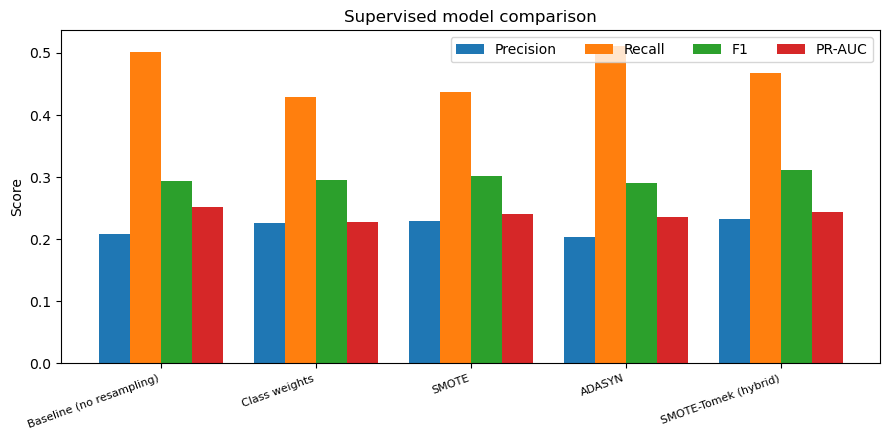

In [23]:
# Metric comparison for the supervised models
sup = res_df[res_df['Model'] != 'Isolation Forest']
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(sup)); w = 0.2
for i, m in enumerate(['Precision','Recall','F1','PR-AUC']):
    ax.bar(x + i*w, sup[m], w, label=m)
ax.set_xticks(x + 1.5*w); ax.set_xticklabels(sup['Model'], rotation=20, ha='right', fontsize=8)
ax.legend(ncol=4); ax.set_ylabel('Score'); ax.set_title('Supervised model comparison')
plt.savefig('image4.png', dpi=300, bbox_inches='tight')

plt.tight_layout(); plt.show()

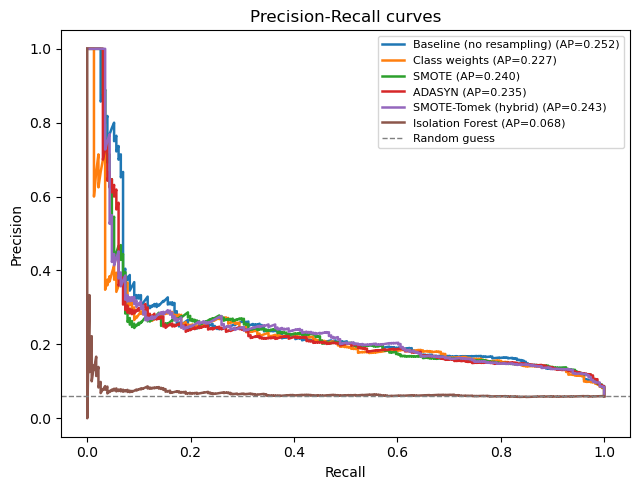

In [24]:
# Precision-recall curves for all models
fig, ax = plt.subplots(figsize=(6.5, 5))
for r in results:
    prec, rec, _ = precision_recall_curve(y_test, r['_scores'])
    ax.plot(rec, prec, label=f"{r['Model']} (AP={r['PR-AUC']:.3f})", lw=1.8)
ax.axhline(y_test.mean(), ls='--', color='grey', lw=1, label='Random guess')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall curves'); ax.legend(fontsize=8)
plt.savefig('image5.png', dpi=300, bbox_inches='tight')

plt.tight_layout(); plt.show()

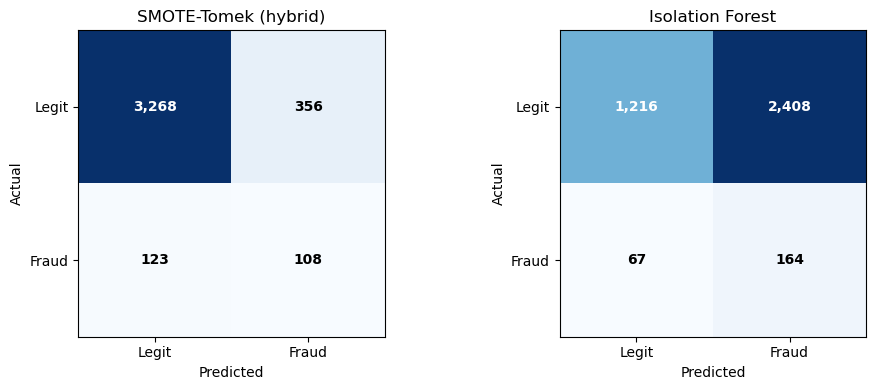

In [21]:
# Confusion matrices: best supervised vs Isolation Forest
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ['SMOTE-Tomek (hybrid)', 'Isolation Forest']):
    r = [x for x in results if x['Model'] == name][0]
    cm = confusion_matrix(y_test, r['_pred'])
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}', ha='center', va='center', fontweight='bold',
                color='white' if v > cm.max()/2 else 'black')
    ax.set_xticks([0,1]); ax.set_xticklabels(['Legit','Fraud'])
    ax.set_yticks([0,1]); ax.set_yticklabels(['Legit','Fraud'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(name)
plt.tight_layout(); plt.show()

## 16. Save the results

Saves the results table to a CSV file.

In [22]:
res_df.to_csv('results_table.csv', index=False)
print('Saved results_table.csv')
res_df

Saved results_table.csv


,Model,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Baseline (no resampling),0.208,0.502,0.294,0.252,0.839
1,Class weights,0.226,0.429,0.296,0.227,0.833
2,SMOTE,0.230,0.437,0.301,0.240,0.836
3,ADASYN,0.203,0.511,0.291,0.235,0.834
4,SMOTE-Tomek (hybrid),0.233,0.468,0.311,0.243,0.837
5,Isolation Forest,0.064,0.710,0.117,0.068,0.513
